In [1]:
import random
from collections import Counter

import chess
import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
def randomMove(board):
    legalMoves=list(board.legal_moves)
    return random.choice(legalMoves)

In [3]:
def playGame(whitePlayer, blackPlayer):
    board=chess.Board()
    while not board.is_game_over():
        player=whitePlayer if board.turn==chess.WHITE else blackPlayer
        board.push(player(board))
    return board.result()

In [13]:
results=[]
for gameNumber in range(20):
    result=playGame(randomMove, randomMove)
    results.append(result)

print(results)
print("White wins:", results.count("1-0"))
print("Black wins:", results.count("0-1"))
print("Draws:", results.count("1/2-1/2"))

['1-0', '0-1', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '0-1']
White wins: 1
Black wins: 2
Draws: 17


In [4]:
def boardToTensor(board):
    tensor=torch.zeros(13,8,8)
    for square,piece in board.piece_map().items():
        planeIndex=piece.piece_type-1
        if piece.color==chess.BLACK:
            planeIndex+=6
        row=square//8
        col=square%8
        tensor[planeIndex,row,col]=1
    if board.turn==chess.WHITE:
        tensor[12,:,:]=1
    return tensor

In [15]:
t=boardToTensor(chess.Board())
print(t.shape)
print(t.sum().item())
print(t[0].sum().item())

torch.Size([13, 8, 8])
96.0
8.0


In [5]:
class ChessNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(13, 64, kernel_size=3, padding=1)
        self.conv2=nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.conv3=nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.policyConv=nn.Conv2d(64, 8, kernel_size=1)
        self.policyHead=nn.Linear(8 * 8 * 8, numMoves)
        self.valueHead =nn.Linear(64 * 8 * 8, 1)

    def forward(self, x):
        turnSign = (2 * x[:, 12, 0, 0] - 1).unsqueeze(1)
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        policy = F.relu(self.policyConv(x))
        policy = self.policyHead(policy.flatten(1))
        value = torch.tanh(self.valueHead(x.flatten(1))) * turnSign
        return policy, value

In [8]:
net=ChessNet()
x=boardToTensor(chess.Board()).unsqueeze(0)
with torch.no_grad():
    policy,value=net(x)

print(x.shape)
print(policy.shape)
print(value.shape)
print(value.item())
print(sum(p.numel() for p in net.parameters()))


torch.Size([1, 13, 8, 8])
torch.Size([1, 4096])
torch.Size([1, 1])
-0.00806561578065157
2187273


In [7]:
numMoves=4096
def moveToIndex(move):
    return move.from_square*64+move.to_square

def indexToMove(index,board):
    fromSquare=index//64
    toSquare=index%64
    piece=board.piece_at(fromSquare)
    promotion=None
    if piece is not None and piece.piece_type == chess.PAWN and chess.square_rank(toSquare) in (0,7):
        promotion=chess.QUEEN
    return chess.Move(fromSquare,toSquare,promotion=promotion)

In [9]:
def legalMovesToMask(board):
    mask=torch.zeros(4096,dtype=torch.bool)
    for move in board.legal_moves:
        mask[moveToIndex(move)]=True
    return mask

def maskedPolicy(policyLogits, board):
    mask = legalMovesToMask(board)
    logits = policyLogits.clone()
    logits[~mask] = float('-inf')
    probs = torch.softmax(logits, dim=0)
    return probs, mask

In [10]:
board=chess.Board()
print(moveToIndex(chess.Move.from_uci("e2e4")))
print(legalMovesToMask(board).sum().item())
print(all(indexToMove(moveToIndex(m), board) == m for m in board.legal_moves))

with torch.no_grad():
    policy,value=net(boardToTensor(board).unsqueeze(0))
probs,mask=maskedPolicy(policy[0],board)
print(probs.sum().item())
print((probs > 0).sum().item())

796
20
True
1.0
20


In [11]:
def netPlayer(board):
    with torch.no_grad():
        policy,value=net(boardToTensor(board).unsqueeze(0))
    probs,mask=maskedPolicy(policy[0], board)
    index=torch.multinomial(probs, 1).item()
    return indexToMove(index, board)

In [24]:
results = [playGame(netPlayer,randomMove) for _ in range(10)]
print(results)

['1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1-0', '1/2-1/2', '1/2-1/2', '1/2-1/2']


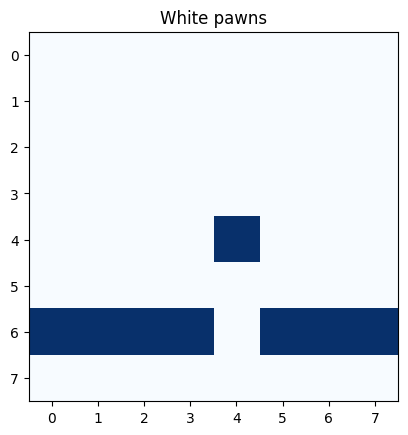

In [25]:
import matplotlib.pyplot as plt

board = chess.Board()
for move in ["e4", "e5", "Nf3", "Nc6", "Bb5"]:
    board.push_san(move)

planes = boardToTensor(board)

plt.imshow(planes[0].flip(0).numpy(), cmap="Blues")
plt.title("White pawns")
plt.show()

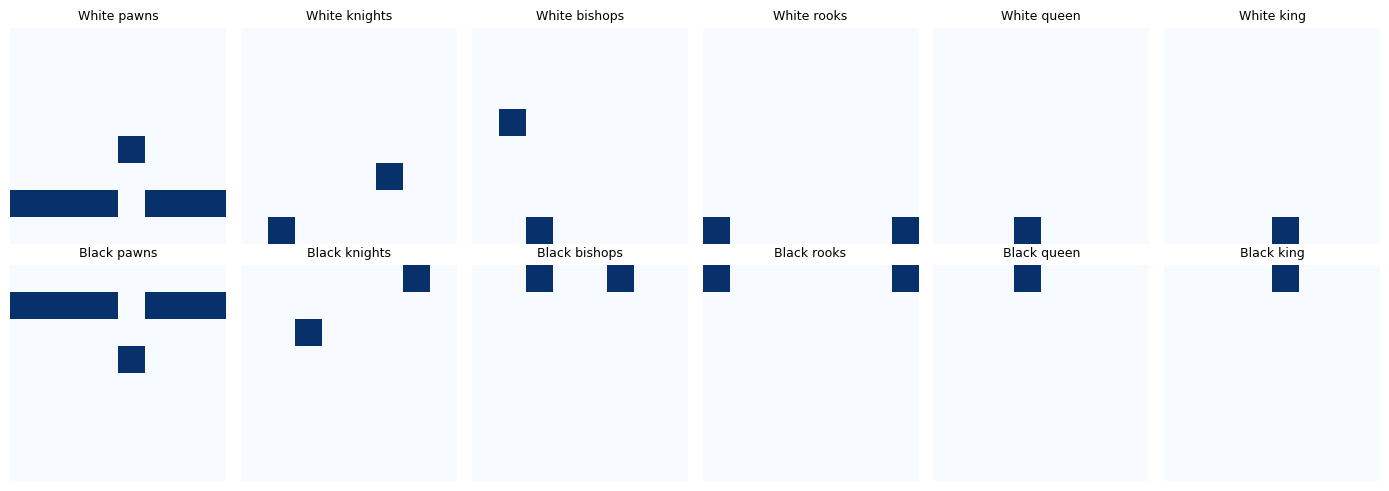

In [ ]:
names = ["White pawns", "White knights", "White bishops", "White rooks", "White queen", "White king",
         "Black pawns", "Black knights", "Black bishops", "Black rooks", "Black queen", "Black king"]

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(planes[i].flip(0).numpy(), cmap="Blues")
    ax.set_title(names[i], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../docs/board_planes.png", dpi=200)
plt.show()

In [12]:
class Node:
    def __init__(self,prior):
        self.prior=prior
        self.visitCount=0
        self.valueSum=0.0
        self.children={}

    def value(self):
        if self.visitCount==0:
            return 0.0
        return self.valueSum/self.visitCount

    def isExpanded(self):
        return len(self.children) >0

In [13]:
root=Node(prior=1.0)
print(root.value(),root.isExpanded())

root.visitCount=4
root.valueSum=2.0
print(root.value())

0.0 False
0.5


In [14]:
def expandNode(node, board, net):
    with torch.no_grad():
        policy,value=net(boardToTensor(board).unsqueeze(0))
    probs,mask=maskedPolicy(policy[0],board)
    for move in board.legal_moves:
        index=moveToIndex(move)
        node.children[index]=Node(prior=probs[index].item())
    return value.item()

In [15]:
board=chess.Board()
root=Node(prior=1.0)
v=expandNode(root,board,net)

print(len(root.children))
print(round(sum(child.prior for child in root.children.values()), 4))
print(round(max(child.prior for child in root.children.values()), 4))
print(v)
print(root.isExpanded())

20
1.0
0.0544
-0.00806561578065157
True


In [16]:
import math

def selectChild(node, cPuct=1.5):
    bestScore= -float('inf')
    bestIndex=None
    bestChild=None
    for index,child in node.children.items():
        explorationBonus=cPuct * child.prior * math.sqrt(max(1, node.visitCount)) / (1 + child.visitCount)
        score= -child.value()+explorationBonus
        if score>bestScore:
            bestScore=score
            bestIndex=index
            bestChild=child
    return bestIndex,bestChild

In [31]:
parent=Node(prior=1.0)
parent.visitCount=10
parent.children[0]=Node(prior=0.6)
parent.children[1]=Node(prior=0.3)
parent.children[2]=Node(prior=0.1)

print(selectChild(parent)[0])

parent.children[0].visitCount=5
parent.children[0].valueSum=4.0
print(selectChild(parent)[0])

parent.children[0].visitCount=2
parent.children[0].valueSum=-1.8
print(selectChild(parent)[0])

0
1
0


In [17]:
def simulate(root,board,net,cPuct=1.5):
    board=board.copy(stack=False)
    node=root
    path=[node]

    while node.isExpanded():
        index,node=selectChild(node, cPuct)
        board.push(indexToMove(index, board))
        path.append(node)

    if board.is_game_over():
        value= -1.0 if board.is_checkmate() else 0.0
    else:
        value=expandNode(node, board, net)

    for n in reversed(path):
        n.visitCount+=1
        n.valueSum+=value
        value= -value

In [ ]:
board=chess.Board()
root=Node(prior=1.0)
for _ in range(50):
    simulate(root, board,net)

print(root.visitCount)
print(len(root.children))
print(sum(child.visitCount for child in root.children.values()))
print(board.fen() == chess.STARTING_FEN)

50
20
49
True


In [ ]:
mateBoard = chess.Board("6k1/5ppp/8/8/8/8/5PPP/R5K1 w - - 0 1")
root = Node(prior=1.0)
for _ in range(200):
    simulate(root, mateBoard, net)

bestIndex = max(root.children, key=lambda i: root.children[i].visitCount)
print(indexToMove(bestIndex, mateBoard))
print(root.children[bestIndex].visitCount)

a1a8
180


In [18]:
def search(board, net, numSimulations=100,cPuct=1.5,addNoise=False):
    root=Node(prior=1.0)
    expandNode(root,board,net)
    if addNoise:
        addRootNoise(root)
    for _ in range(numSimulations):
        simulate(root, board,net,cPuct)

    visitCounts=torch.zeros(numMoves)
    for index,child in root.children.items():
        visitCounts[index]=child.visitCount

    return visitCounts/visitCounts.sum(),root

In [ ]:
board=chess.Board()
visitProbs,root=search(board,net,numSimulations=100)
print(visitProbs.shape)
print(round(visitProbs.sum().item(),4))
print((visitProbs>0).sum().item())

top=torch.topk(visitProbs,3)
for p,index in zip(top.values,top.indices):
    print(indexToMove(index.item(),board),round(p.item(),3))

torch.Size([4096])
1.0
20
g1h3 0.051
g1f3 0.051
b1a3 0.051


In [ ]:
mateBoard=chess.Board("6k1/5ppp/8/8/8/8/5PPP/R5K1 w - - 0 1")
visitProbs,root=search(mateBoard,net,numSimulations=100)
print(indexToMove(torch.argmax(visitProbs).item(), mateBoard), round(visitProbs.max().item(), 2))

a1a8 0.87


In [19]:
def makeMCTSPlayer(net,numSimulations=50,cPuct=1.5):
    def player(board):
        visitProbs,root=search(board,net,numSimulations, cPuct)
        index=torch.argmax(visitProbs).item()
        return indexToMove(index,board)
    return player

In [35]:
import time

start=time.time()
search(chess.Board(),net,numSimulations=50)
print(round(time.time()-start,2), "seconds")

0.23 seconds


In [21]:
def selfPlayGame(net, numSimulations=50, temperatureMoves=15, maxMoves=200,
                 startFen=None, pgnPath=None, adjudicate=False, materialTargets=False, cPuct=1.5):
    board = chess.Board(startFen) if startFen else chess.Board()
    history = []
    moveCount = 0

    while not board.is_game_over() and moveCount < maxMoves:
        visitProbs, root = search(board, net, numSimulations, cPuct, addNoise=True)
        history.append((boardToTensor(board), visitProbs, board.turn, materialBalance(board)))

        if moveCount < temperatureMoves:
            index = torch.multinomial(visitProbs, 1).item()
        else:
            index = torch.argmax(visitProbs).item()

        board.push(indexToMove(index, board))
        moveCount += 1

    winner = None
    whiteScore = 0.0
    if board.is_checkmate():
        winner = not board.turn
    elif adjudicate and not (board.is_stalemate() or board.is_insufficient_material()):
        whiteScore = 0.5 * math.tanh(materialBalance(board) / 5)

    examples = []
    for state, probs, turn, balance in history:
        if materialTargets:
            moverBalance = balance if turn == chess.WHITE else -balance
            z = 0.5 * math.tanh(moverBalance / 5)
        elif winner is not None:
            z = 1.0 if turn == winner else -1.0
        else:
            z = whiteScore if turn == chess.WHITE else -whiteScore
        examples.append((state, probs, z))

    if pgnPath is not None:
        saveGame(board, pgnPath, white="Self-play", black="Self-play")

    return examples, board.result()

In [ ]:
examples,result=selfPlayGame(net, numSimulations=25, maxMoves=30)
print(len(examples),result)
state,probs,z=examples[0]
print(state.shape,probs.shape,round(probs.sum().item(), 4), z)
print(set(z for _, _, z in examples))

30 *
torch.Size([13, 8, 8]) torch.Size([4096]) 1.0 0.0
{0.0}


In [ ]:
for fen in ["6k1/5ppp/8/8/8/8/5PPP/R5K1 w - - 0 1",
            "6k1/8/8/8/8/8/r4PPP/6K1 b - - 0 1"]:
    examples,result=selfPlayGame(net,numSimulations=50,temperatureMoves=0,startFen=fen)
    print(len(examples),result, [z for _, _, z in examples])

1 1-0 [1.0]
1 0-1 [1.0]


In [22]:
import torch.optim as optim
optimizer = optim.Adam(net.parameters(),lr=1e-3)

def trainStep(net,optimizer,batch):
    states=torch.stack([s for s, _, _ in batch])
    targetPolicies=torch.stack([p for _, p, _ in batch])
    targetValues=torch.tensor([z for _, _, z in batch],dtype=torch.float32).unsqueeze(1)

    policyLogits,values=net(states)
    policyLoss= -(targetPolicies*F.log_softmax(policyLogits,dim=1)).sum(dim=1).mean()
    valueLoss=F.mse_loss(values,targetValues)
    loss=policyLoss+valueLoss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return policyLoss.item(),valueLoss.item()

In [ ]:
batch=[]
for _ in range(3):
    examples,_=selfPlayGame(net,numSimulations=25,maxMoves=20)
    batch.extend(examples)
print(len(batch))

for step in range(101):
    policyLoss, valueLoss=trainStep(net,optimizer,batch)
    if step%25==0:
        print(step,round(policyLoss,3),round(valueLoss,4))

60
0 8.313 0.0001
25 4.136 0.0133
50 3.587 0.0027
75 3.286 0.0009
100 3.193 0.0126


In [23]:
from collections import deque
import random

replayBuffer=deque(maxlen=20000)

def sampleBatch(replayBuffer,batchSize=64):
    return random.sample(list(replayBuffer),min(batchSize,len(replayBuffer)))

def trainOnBuffer(net,optimizer,replayBuffer,numSteps=100,batchSize=64):
    policyLosses=[]
    valueLosses=[]
    for _ in range(numSteps):
        batch=sampleBatch(replayBuffer, batchSize)
        policyLoss,valueLoss=trainStep(net, optimizer, batch)
        policyLosses.append(policyLoss)
        valueLosses.append(valueLoss)
    return sum(policyLosses)/len(policyLosses),sum(valueLosses)/len(valueLosses)

In [24]:
def playGameCapped(whitePlayer,blackPlayer,maxPlies=200):
    board=chess.Board()
    while not board.is_game_over() and len(board.move_stack)<maxPlies:
        player=whitePlayer if board.turn==chess.WHITE else blackPlayer
        board.push(player(board))
    return board.result(),board

def evaluate(player,opponent=randomMove,numGames=6,maxPlies=200):
    wins=0
    draws=0
    losses=0
    for i in range(numGames):
        playerIsWhite=(i%2==0)
        if playerIsWhite:
            result,board=playGameCapped(player,opponent,maxPlies)
        else:
            result,board=playGameCapped(opponent,player,maxPlies)

        if result == "1-0":
            playerResult = 1 if playerIsWhite else -1
        elif result == "0-1":
            playerResult = -1 if playerIsWhite else 1
        else:
            playerResult = 0

        if playerResult>0:
            wins+=1
        elif playerResult<0:
            losses+=1
        else:
            draws+=1

    score=(wins+0.5*draws)/numGames
    return wins,draws,losses,score

In [25]:
import chess.pgn

def saveGame(board,path,white="White",black="Black"):
    game = chess.pgn.Game.from_board(board)
    game.headers["White"]=white
    game.headers["Black"]=black
    with open(path, "w") as f:
        f.write(str(game)+"\n")

In [ ]:
net.load_state_dict(torch.load("../checkpoints/gen_000.pt", map_location="cpu"))
gen0Player=makeMCTSPlayer(net,numSimulations=25)

print(evaluate(gen0Player,randomMove,numGames=6))

(1, 4, 1, 0.5)


In [26]:
import csv
import os
import time

def trainLoop(net,optimizer,buffer,runName,numGenerations=10,gamesPerGeneration=10,
              numSimulations=50,selfPlayMaxMoves=200,trainSteps=100,batchSize=64,
              evalEvery=1,evalGames=6,evalSimulations=25,evalMaxPlies=200,
              checkpointEvery=1,startGeneration=1,adjudicate=False,materialTargets=False,cPuct=1.5):

    os.makedirs("../logs",exist_ok=True)
    os.makedirs(f"../checkpoints/{runName}",exist_ok=True)
    os.makedirs(f"../games/{runName}",exist_ok=True)

    logPath= f"../logs/{runName}_metrics.csv"
    columns=["generation","selfPlayGames","decisiveGames","bufferSize",
               "policyLoss","valueLoss","evalWins","evalDraws","evalLosses",
               "evalScore","seconds"]
    if not os.path.exists(logPath):
        with open(logPath, "w",newline="") as f:
            csv.writer(f).writerow(columns)

    for generation in range(startGeneration,startGeneration+numGenerations):
        startTime=time.time()

        decisiveGames=0 # games that ended in checkmate or resignation
        for gameNumber in range(gamesPerGeneration):
            pgnPath=None
            if gameNumber==0:
                pgnPath = f"../games/{runName}/gen_{generation:03d}_selfplay.pgn"
            examples, result = selfPlayGame(net, numSimulations, maxMoves=selfPlayMaxMoves, pgnPath=pgnPath, adjudicate=adjudicate, materialTargets=materialTargets, cPuct=cPuct)
            buffer.extend(examples)
            if result in ("1-0", "0-1"):
                decisiveGames+=1

        policyLoss,valueLoss=trainOnBuffer(net,optimizer,buffer,trainSteps,batchSize)

        evalWins,evalDraws,evalLosses,evalScore="","","",""
        if generation % evalEvery==0:
            player=makeMCTSPlayer(net, evalSimulations)
            evalWins,evalDraws,evalLosses,evalScore=evaluate(player, randomMove, evalGames, evalMaxPlies)

        with open(logPath, "a", newline="") as f:
            csv.writer(f).writerow([generation, gamesPerGeneration, decisiveGames, len(buffer),
                                    round(policyLoss, 4), round(valueLoss, 4),
                                    evalWins, evalDraws, evalLosses, evalScore,
                                    round(time.time() - startTime)])

        if generation % checkpointEvery==0:
            torch.save(net.state_dict(), f"../checkpoints/{runName}/gen_{generation:03d}.pt")

        print(generation, round(policyLoss, 3), round(valueLoss, 4), decisiveGames, evalScore)

In [27]:
import cProfile
import pstats

def profileSearch(board, numSimulations=50):
    profiler = cProfile.Profile()
    profiler.enable()
    search(board, net, numSimulations)
    profiler.disable()
    pstats.Stats(profiler).sort_stats("tottime").print_stats(12)

net.load_state_dict(torch.load("../checkpoints/gen_000.pt", map_location="cpu"))

print("--- opening position ---")
profileSearch(chess.Board())

midBoard = chess.Board()
for _ in range(100):
    if midBoard.is_game_over():
        break
    midBoard.push(randomMove(midBoard))

print("--- after 100 random plies ---")
profileSearch(midBoard)

--- opening position ---
         53063 function calls (52446 primitive calls) in 0.220 seconds

   Ordered by: internal time
   List reduced from 240 to 12 due to restriction <12>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      102    0.037    0.000    0.037    0.000 {built-in method torch._C._nn.linear}
       51    0.035    0.001    0.047    0.001 C:\Users\yasmi\AppData\Local\Temp\ipykernel_24196\2728838808.py:1(boardToTensor)
      204    0.020    0.000    0.020    0.000 {built-in method torch.conv2d}
       51    0.018    0.000    0.037    0.001 C:\Users\yasmi\AppData\Local\Temp\ipykernel_24196\2668331044.py:1(legalMovesToMask)
       51    0.014    0.000    0.201    0.004 C:\Users\yasmi\AppData\Local\Temp\ipykernel_24196\1244860893.py:1(expandNode)
     2328    0.010    0.000    0.023    0.000 c:\Users\yasmi\miniconda3\Lib\site-packages\chess\__init__.py:1819(generate_pseudo_legal_moves)
       51    0.007    0.000    0.077    0.002 C:\Users\yasmi\A

In [62]:
import time

start=time.time()
search(chess.Board(),net,numSimulations=50)
print(round(time.time()-start,2),"seconds")

0.38 seconds


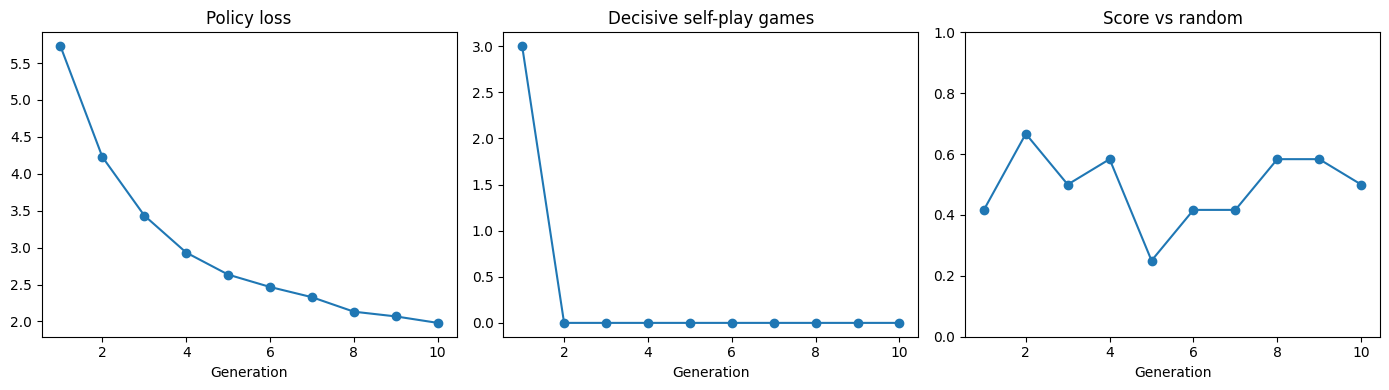

In [63]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv("../logs/run1_metrics.csv")
fig,axes=plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(df["generation"], df["policyLoss"], marker="o")
axes[0].set_title("Policy loss")

axes[1].plot(df["generation"], df["decisiveGames"], marker="o")
axes[1].set_title("Decisive self-play games")

axes[2].plot(df["generation"], df["evalScore"], marker="o")
axes[2].set_title("Score vs random")
axes[2].set_ylim(0, 1)

for ax in axes:
    ax.set_xlabel("Generation")
plt.tight_layout()
plt.savefig("../docs/run1_curves.png", dpi=200)
plt.show()

In [28]:
pieceValues={chess.PAWN:1,chess.KNIGHT:3,chess.BISHOP:3,chess.ROOK:5,chess.QUEEN:9}

def materialBalance(board):
    balance=0
    for piece in board.piece_map().values():
        if piece.piece_type==chess.KING:
            continue
        value=pieceValues[piece.piece_type]
        balance+=value if piece.color==chess.WHITE else -value
    return balance

In [ ]:
print(materialBalance(chess.Board()))
b = chess.Board()
b.remove_piece_at(chess.D8)
print(materialBalance(b))

for fen in ["4k3/8/8/8/8/8/8/3QK3 w - - 0 1", "3qk3/8/8/8/8/8/8/4K3 b - - 0 1"]:
    for adj in (False, True):
        examples, result = selfPlayGame(net, numSimulations=10, temperatureMoves=0,
                                        maxMoves=1, startFen=fen, adjudicate=adj)
        print(adj, result, [round(z, 3) for _, _, z in examples])

0
9
False * [0.0]
True * [0.473]
False * [-0.0]
True * [0.473]


In [ ]:
import chess.pgn

runName = "run2"
for g in range(1, 11):
    with open(f"../games/{runName}/gen_{g:03d}_selfplay.pgn") as f:
        game = chess.pgn.read_game(f)
    plies = len(list(game.mainline_moves()))
    print(g, "plies:", plies, "result:", game.headers["Result"],
          "material:", materialBalance(game.end().board()))

1 plies: 31 result: 1/2-1/2 material: 0
2 plies: 61 result: 1/2-1/2 material: -4
3 plies: 54 result: 1/2-1/2 material: -1
4 plies: 77 result: 1/2-1/2 material: -7
5 plies: 70 result: 1/2-1/2 material: -5
6 plies: 44 result: 1/2-1/2 material: 0
7 plies: 58 result: 1/2-1/2 material: 0
8 plies: 38 result: 1/2-1/2 material: 0
9 plies: 42 result: 1/2-1/2 material: 0
10 plies: 42 result: 1/2-1/2 material: 0


In [29]:
def evaluateDetailed(player,opponent=randomMove,numGames=30,maxPlies=200):
    wins=0
    draws=0
    losses=0
    margins=[]
    for i in range(numGames):
        playerIsWhite=(i%2==0)
        if playerIsWhite:
            result,board=playGameCapped(player,opponent,maxPlies)
        else:
            result,board=playGameCapped(opponent,player,maxPlies)

        balance=materialBalance(board)
        margins.append(balance if playerIsWhite else -balance)

        if result == "1-0":
            playerResult = 1 if playerIsWhite else -1
        elif result == "0-1":
            playerResult = -1 if playerIsWhite else 1
        else:
            playerResult=0

        if playerResult>0:
            wins+=1
        elif playerResult<0:
            losses+=1
        else:
            draws+=1

    score=(wins+0.5*draws)/numGames
    return wins,draws,losses,round(score,3),round(sum(margins)/len(margins),2)

In [30]:
import numpy as np
def addRootNoise(root,alpha=0.3,fraction=0.25):
    indices=list(root.children.keys())
    noise=np.random.dirichlet([alpha] * len(indices))
    for index, n in zip(indices,noise):
        child=root.children[index]
        child.prior=(1-fraction) * child.prior+fraction*n

In [67]:
board=chess.Board()
for noise in (False, True):
    visitProbs, root = search(board, net, numSimulations=100, addNoise=noise)
    print(noise, root.visitCount, round(sum(c.prior for c in root.children.values()), 4), round(visitProbs.max().item(), 3))

False 100 1.0 0.05
True 100 1.0 0.11


In [68]:
net.load_state_dict(torch.load("../checkpoints/gen_000.pt", map_location="cpu"))
optimizer = optim.Adam(net.parameters(), lr=1e-3)
replayBuffer.clear()

trainLoop(net, optimizer,replayBuffer,runName="run3",
          numGenerations=10,gamesPerGeneration=8,numSimulations=40,
          selfPlayMaxMoves=200,trainSteps=100,batchSize=64,
          evalEvery=2,evalGames=12,evalSimulations=25,evalMaxPlies=200,
          adjudicate=True)

1 6.65 0.3693 5 
2 5.411 0.0665 0 0.4166666666666667
3 4.368 0.0828 1 
4 3.85 0.0574 0 0.5
5 3.576 0.0523 0 
6 3.344 0.0443 0 0.4583333333333333
7 3.198 0.0431 0 
8 3.05 0.0327 0 0.4583333333333333
9 2.995 0.0345 0 
10 2.935 0.03 0 0.5


In [32]:
class AblatedNet(nn.Module):
    def __init__(self, base, uniformPolicy=False, zeroValue=False):
        super().__init__()
        self.base = base
        self.uniformPolicy = uniformPolicy
        self.zeroValue = zeroValue

    def forward(self, x):
        policy, value = self.base(x)
        if self.uniformPolicy:
            policy = torch.zeros_like(policy)
        if self.zeroValue:
            value = torch.zeros_like(value)
        return policy, value


def loadNet(path):
    n = ChessNet()
    n.load_state_dict(torch.load(path, map_location="cpu"))
    return n

In [33]:
def valueVsMaterial(net, numPositions=300):
    values, materials = [], []
    board = chess.Board()
    while len(values) < numPositions:
        if board.is_game_over():
            board = chess.Board()
        with torch.no_grad():
            _, value = net(boardToTensor(board).unsqueeze(0))
        balance = materialBalance(board)
        values.append(value.item())
        materials.append(balance if board.turn == chess.WHITE else -balance)
        board.push(randomMove(board))
    return torch.corrcoef(torch.tensor([values, materials]))[0, 1].item()

print("Gen 0:", valueVsMaterial(loadNet("../checkpoints/gen_000.pt")))
print("Run 4, gen 10:", valueVsMaterial(loadNet("../checkpoints/run4/gen_010.pt")))

Gen 0: 0.031183447688817978
Run 4, gen 10: 0.026930969208478928


In [74]:
net.load_state_dict(torch.load("../checkpoints/gen_000.pt", map_location="cpu"))
optimizer = optim.Adam(net.parameters(), lr=1e-3)
replayBuffer.clear()

trainLoop(net, optimizer, replayBuffer, runName="run4",
          numGenerations=10, gamesPerGeneration=8, numSimulations=40,
          selfPlayMaxMoves=200, trainSteps=30, batchSize=64,
          evalEvery=5, evalGames=6, evalSimulations=25, evalMaxPlies=200,
          materialTargets=True)

1 7.176 0.7466 7 
2 6.301 0.4466 3 
3 5.777 0.3113 2 
4 5.449 0.2504 1 
5 5.183 0.1846 1 0.3333333333333333
6 4.964 0.1555 0 
7 4.793 0.1406 0 
8 4.637 0.1173 1 
9 4.533 0.1228 1 
10 4.41 0.1132 0 0.5


In [76]:
gen0 = loadNet("../checkpoints/gen_000.pt")
run4Gen5 = loadNet("../checkpoints/run4/gen_005.pt")
run4Gen10 = loadNet("../checkpoints/run4/gen_010.pt")

print("value vs material correlation")
for name, n in [("Gen 0", gen0), ("Run 4, gen 5", run4Gen5), ("Run 4, gen 10", run4Gen10)]:
    print(name, round(valueVsMaterial(n), 3))

for name, n in [("Run 4, gen 5", run4Gen5), ("Run 4, gen 10", run4Gen10)]:
    player = makeMCTSPlayer(n, numSimulations=25)
    print(name, evaluateDetailed(player, randomMove, numGames=30))

value vs material correlation
Gen 0 0.191
Run 4, gen 5 -0.001
Run 4, gen 10 -0.26
Run 4, gen 5 (1, 24, 5, 0.433, -12.3)
Run 4, gen 10 (2, 26, 2, 0.5, -9.43)


In [34]:
def makeMaterialData(numPositions):
    states, targets = [], []
    board = chess.Board()
    maxPlies = random.randint(20, 120)
    while len(states) < numPositions:
        if board.is_game_over() or len(board.move_stack) >= maxPlies:
            board = chess.Board()
            maxPlies = random.randint(20, 120)
        balance = materialBalance(board)
        moverBalance = balance if board.turn == chess.WHITE else -balance
        states.append(boardToTensor(board))
        targets.append(0.5 * math.tanh(moverBalance / 5))
        board.push(randomMove(board))
    return torch.stack(states), torch.tensor(targets).unsqueeze(1)


def testValueLearning(steps=300, batchSize=64):
    trainStates, trainTargets = makeMaterialData(4000)
    testStates, testTargets = makeMaterialData(1000)
    testNet = ChessNet()
    opt = optim.Adam(testNet.parameters(), lr=1e-3)
    for step in range(steps):
        idx = torch.randint(0, len(trainStates), (batchSize,))
        _, values = testNet(trainStates[idx])
        loss = F.mse_loss(values, trainTargets[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 100 == 0:
            print(step, round(loss.item(), 4))
    with torch.no_grad():
        _, testValues = testNet(testStates)
    return torch.corrcoef(torch.stack([testValues.flatten(), testTargets.flatten()]))[0, 1].item()


print("correlation on unseen positions:", round(testValueLearning(), 3))

0 0.083
100 0.0147
200 0.0039
correlation on unseen positions: 0.016


In [38]:
def makeMaterialData(numPositions):
    states, targets = [], []
    while len(states) < numPositions:
        board = chess.Board()
        for _ in range(random.randint(0, 80)):
            if board.is_game_over():
                break
            board.push(randomMove(board))
        board.turn = random.choice([chess.WHITE, chess.BLACK])
        pieces = [sq for sq, p in board.piece_map().items() if p.piece_type != chess.KING]
        for sq in random.sample(pieces, random.randint(0, min(12, len(pieces)))):
            board.remove_piece_at(sq)
        balance = materialBalance(board)
        moverBalance = balance if board.turn == chess.WHITE else -balance
        states.append(boardToTensor(board))
        targets.append(0.5 * math.tanh(moverBalance / 5))
    return torch.stack(states), torch.tensor(targets).unsqueeze(1)


class ChessNetSigned(ChessNet):
    def forward(self, x):
        turnSign = (2 * x[:, 12, 0, 0] - 1).unsqueeze(1)
        policy, value = super().forward(x)
        return policy, value * turnSign


trainStates, trainTargets = makeMaterialData(4000)
testStates, testTargets = makeMaterialData(1000)
print("label variance:", round(trainTargets.var().item(), 3))


def corr(a, b):
    return torch.corrcoef(torch.stack([a.flatten(), b.flatten()]))[0, 1].item()


def testValueLearning(netClass, steps=400, batchSize=64):
    testNet = netClass()
    opt = optim.Adam(testNet.parameters(), lr=1e-3)
    for step in range(steps):
        idx = torch.randint(0, len(trainStates), (batchSize,))
        _, values = testNet(trainStates[idx])
        loss = F.mse_loss(values, trainTargets[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
    with torch.no_grad():
        _, trainValues = testNet(trainStates)
        _, testValues = testNet(testStates)
    return round(corr(trainValues, trainTargets), 3), round(corr(testValues, testTargets), 3)


for name, netClass in [("plain", ChessNet), ("signed", ChessNetSigned)]:
    print(name, "(train corr, test corr):", testValueLearning(netClass))

label variance: 0.137
plain (train corr, test corr): (0.945, 0.919)
signed (train corr, test corr): (0.912, 0.825)


In [81]:
for name, path in [("Gen 0", "../checkpoints/gen_000.pt"),
                   ("Run 3, gen 10", "../checkpoints/run3/gen_010.pt"),
                   ("Run 4, gen 10", "../checkpoints/run4/gen_010.pt")]:
    n = loadNet(path)
    with torch.no_grad():
        _, v = n(testStates)
    print(name, round(corr(v, testTargets), 3))

Gen 0 0.007
Run 3, gen 10 -0.062
Run 4, gen 10 -0.033


In [40]:
def pretrainValue(net, states, targets, steps=500, batchSize=64, lr=1e-3):
    opt = optim.Adam(net.parameters(), lr=lr)
    for step in range(steps):
        idx = torch.randint(0, len(states), (batchSize,))
        _, values = net(states[idx])
        loss = F.mse_loss(values, targets[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
    return net

In [84]:
mateFens = ["6k1/5ppp/8/8/8/8/5PPP/R5K1 w - - 0 1",
            "6k1/8/8/8/8/8/r4PPP/6K1 b - - 0 1",
            "7k/5Q2/6K1/8/8/8/8/8 w - - 0 1",
            "k7/8/1K6/8/8/8/8/7R w - - 0 1",
            "r1bqkb1r/pppp1ppp/2n2n2/4p2Q/2B1P3/8/PPPP1PPP/RNB1K1NR w KQkq - 4 4"]

def findsMate(net, fen, numSimulations, cPuct):
    board = chess.Board(fen)
    visitProbs, root = search(board, net, numSimulations, cPuct)
    board.push(indexToMove(torch.argmax(visitProbs).item(), board))
    return board.is_checkmate()

nets = {"Gen 0": loadNet("../checkpoints/gen_000.pt"),
        "Pretrained value": loadNet("../checkpoints/gen_000_pre.pt")}

for name, n in nets.items():
    for cPuct in (1.5, 4.0):
        found = sum(findsMate(n, fen, 25, cPuct) for fen in mateFens)
        print(name, "cPuct", cPuct, "-> found", found, "of", len(mateFens))

Gen 0 cPuct 1.5 -> found 5 of 5
Gen 0 cPuct 4.0 -> found 5 of 5
Pretrained value cPuct 1.5 -> found 3 of 5
Pretrained value cPuct 4.0 -> found 5 of 5


In [85]:
for name, n in nets.items():
    player=makeMCTSPlayer(n,numSimulations=25,cPuct=4.0)
    print(name,"cPuct 4.0",evaluateDetailed(player,randomMove,numGames=30))

Gen 0 cPuct 4.0 (10, 20, 0, 0.667, 0.33)
Pretrained value cPuct 4.0 (3, 25, 2, 0.517, 6.43)


In [88]:
net.load_state_dict(torch.load("../checkpoints/gen_000_pre.pt", map_location="cpu"))
optimizer = optim.Adam(net.parameters(), lr=3e-4)
replayBuffer.clear()

trainLoop(net, optimizer, replayBuffer, runName="run5",
          numGenerations=10, gamesPerGeneration=8, numSimulations=40,
          selfPlayMaxMoves=200, trainSteps=30, batchSize=64,
          evalEvery=5, evalGames=6, evalSimulations=25, evalMaxPlies=200,
          materialTargets=True, cPuct=4.0)

1 8.188 0.164 3 
2 7.291 0.1373 5 
3 6.7 0.1077 6 
4 6.411 0.0779 2 
5 5.887 0.0482 1 0.5833333333333334
6 5.734 0.0413 0 
7 5.53 0.0327 1 
8 5.396 0.0273 0 
9 5.352 0.0252 0 
10 5.232 0.0258 0 0.4166666666666667


In [89]:
import chess.pgn

for g in range(1, 11):
    with open(f"../games/run5/gen_{g:03d}_selfplay.pgn") as f:
        game = chess.pgn.read_game(f)
    plies = len(list(game.mainline_moves()))
    print(g, "plies:", plies, "result:", game.headers["Result"],
          "material:", materialBalance(game.end().board()))

1 plies: 200 result: * material: -14
2 plies: 200 result: * material: -10
3 plies: 123 result: 1-0 material: -7
4 plies: 200 result: * material: -9
5 plies: 90 result: 0-1 material: -1
6 plies: 72 result: 1/2-1/2 material: -1
7 plies: 168 result: 0-1 material: -12
8 plies: 106 result: 1/2-1/2 material: 8
9 plies: 105 result: 1/2-1/2 material: -1
10 plies: 48 result: 1/2-1/2 material: 0


In [90]:
for name, path in [("Run 5, gen 5", "../checkpoints/run5/gen_005.pt"),
                   ("Run 5, gen 10", "../checkpoints/run5/gen_010.pt")]:
    n=loadNet(path)
    player=makeMCTSPlayer(n,numSimulations=25,cPuct=4.0)
    print(name,evaluateDetailed(player,randomMove,numGames=30))

Run 5, gen 5 (0, 24, 6, 0.4, -10.87)
Run 5, gen 10 (0, 25, 5, 0.417, -13.6)


In [41]:
def randomPosition():
    board = chess.Board()
    for _ in range(random.randint(0, 80)):
        if board.is_game_over():
            break
        board.push(randomMove(board))
    return board


def priorSharpness(net, numPositions=200):
    ratios = []
    while len(ratios) < numPositions:
        board = randomPosition()
        if board.is_game_over():
            continue
        with torch.no_grad():
            policy, _ = net(boardToTensor(board).unsqueeze(0))
        probs, mask = maskedPolicy(policy[0], board)
        ratios.append(probs.max().item() * mask.sum().item())
    return round(sum(ratios) / len(ratios), 2)


def evaluateByColor(player, opponent=randomMove, gamesPerColor=15, maxPlies=200):
    out = {}
    for colorName, playerIsWhite in [("White", True), ("Black", False)]:
        wins = draws = losses = 0
        margins = []
        for _ in range(gamesPerColor):
            if playerIsWhite:
                result, board = playGameCapped(player, opponent, maxPlies)
            else:
                result, board = playGameCapped(opponent, player, maxPlies)
            balance = materialBalance(board)
            margins.append(balance if playerIsWhite else -balance)
            if result == "1-0":
                playerResult = 1 if playerIsWhite else -1
            elif result == "0-1":
                playerResult = -1 if playerIsWhite else 1
            else:
                playerResult = 0
            wins += playerResult > 0
            losses += playerResult < 0
            draws += playerResult == 0
        out[colorName] = (wins, draws, losses, round(sum(margins) / len(margins), 2))
    return out

In [43]:
def collectDistillationData(net, numPositions, numSimulations=100, cPuct=4.0):
    examples = []
    while len(examples) < numPositions:
        board = randomPosition()
        if board.is_game_over():
            continue
        visitProbs, root = search(board, net, numSimulations, cPuct)
        balance = materialBalance(board)
        moverBalance = balance if board.turn == chess.WHITE else -balance
        examples.append((boardToTensor(board), visitProbs, 0.5 * math.tanh(moverBalance / 5)))
    return examples


def policyLossOn(net, examples):
    states = torch.stack([s for s, _, _ in examples])
    targets = torch.stack([p for _, p, _ in examples])
    with torch.no_grad():
        logits, _ = net(states)
    return round(-(targets * F.log_softmax(logits, dim=1)).sum(dim=1).mean().item(), 3)


distillNet = loadNet("../checkpoints/gen_000_pre.pt")
distillOptimizer = optim.Adam(distillNet.parameters(), lr=1e-3)

start = time.time()
trainData = collectDistillationData(distillNet, 2000)
heldOut = collectDistillationData(distillNet, 300)
print("collected in", round(time.time() - start), "s")

print("held-out policy loss before training:", policyLossOn(distillNet, heldOut))
distillBuffer = deque(trainData, maxlen=20000)
for chunk in range(3):
    print("chunk", chunk, "train losses (policy, value):", trainOnBuffer(distillNet, distillOptimizer, distillBuffer, numSteps=100, batchSize=64))
print("held-out policy loss after training:", policyLossOn(distillNet, heldOut))

torch.save(distillNet.state_dict(), "../checkpoints/distill_gen1_trial.pt")

collected in 1126 s
held-out policy loss before training: 8.311
chunk 0 train losses (policy, value): (6.733942909240723, 0.028927669590339065)
chunk 1 train losses (policy, value): (6.017737832069397, 0.018360880529507996)
chunk 2 train losses (policy, value): (5.735289177894592, 0.021837014006450772)
held-out policy loss after training: 6.152


In [94]:
player=makeMCTSPlayer(distillNet, numSimulations=25, cPuct=4.0)
print("distilled:", evaluateDetailed(player,randomMove,numGames=30))

ablated=AblatedNet(distillNet, uniformPolicy=True)
print("distilled, policy ignored:", evaluateDetailed(makeMCTSPlayer(ablated, 25, 4.0), randomMove, numGames=30))
print("prior sharpness:", priorSharpness(distillNet))

distilled: (7, 22, 1, 0.6, 3.77)
distilled, policy ignored: (2, 26, 2, 0.5, 5.87)
prior sharpness: 4.84


In [44]:
def distillLoop(net, optimizer, buffer, heldOut, runName, numGenerations=4,
                positionsPerGeneration=2000, teacherSimulations=100, cPuct=4.0,
                trainSteps=300, batchSize=64, evalGames=30, evalSimulations=25, startGeneration=2):

    os.makedirs("../logs", exist_ok=True)
    os.makedirs(f"../checkpoints/{runName}", exist_ok=True)
    logPath = f"../logs/{runName}_metrics.csv"
    columns = ["generation", "positions", "bufferSize", "policyLoss", "valueLoss", "heldOutLoss",
               "wins", "draws", "losses", "score", "margin", "seconds"]
    if not os.path.exists(logPath):
        with open(logPath, "w", newline="") as f:
            csv.writer(f).writerow(columns)

    for generation in range(startGeneration, startGeneration + numGenerations):
        startTime = time.time()

        data = collectDistillationData(net, positionsPerGeneration, teacherSimulations, cPuct)
        buffer.extend(data)

        policyLoss, valueLoss = trainOnBuffer(net, optimizer, buffer, trainSteps, batchSize)
        heldOutLoss = policyLossOn(net, heldOut)

        player = makeMCTSPlayer(net, evalSimulations, cPuct)
        wins, draws, losses, score, margin = evaluateDetailed(player, randomMove, evalGames)

        with open(logPath, "a", newline="") as f:
            csv.writer(f).writerow([generation, positionsPerGeneration, len(buffer),
                                    round(policyLoss, 4), round(valueLoss, 4), heldOutLoss,
                                    wins, draws, losses, score, margin, round(time.time() - startTime)])

        torch.save(net.state_dict(), f"../checkpoints/{runName}/gen_{generation:03d}.pt")
        print(generation, round(policyLoss, 3), round(valueLoss, 4), heldOutLoss, (wins, draws, losses, score, margin))

In [97]:
distillLoop(distillNet,distillOptimizer,deque(trainData,maxlen=6000),heldOut,"test_distill",
            numGenerations=1,positionsPerGeneration=10,teacherSimulations=10,
            trainSteps=5,evalGames=2,startGeneration=99)

99 5.348 0.0292 6.162 (0, 2, 0, 0.5, 5.5)


In [98]:
distillNet.load_state_dict(torch.load("../checkpoints/distill_gen1_trial.pt", map_location="cpu"))
distillOptimizer = optim.Adam(distillNet.parameters(), lr=1e-3)
distillBuffer = deque(trainData, maxlen=6000)

with open("../logs/distill_metrics.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["generation", "positions", "bufferSize", "policyLoss", "valueLoss", "heldOutLoss",
                     "wins", "draws", "losses", "score", "margin", "seconds"])
    writer.writerow([1, 2000, 2000, 5.6342, 0.0237, 6.161, 7, 22, 1, 0.6, 3.77, ""])

distillLoop(distillNet, distillOptimizer, distillBuffer, heldOut, "distill", numGenerations=4)

2 4.469 0.0304 6.096 (7, 22, 1, 0.6, 1.83)
3 3.605 0.0245 5.929 (6, 23, 1, 0.583, 0.7)
4 2.89 0.0209 6.191 (2, 24, 4, 0.467, -6.8)
5 2.585 0.0216 6.575 (0, 26, 4, 0.433, -5.27)


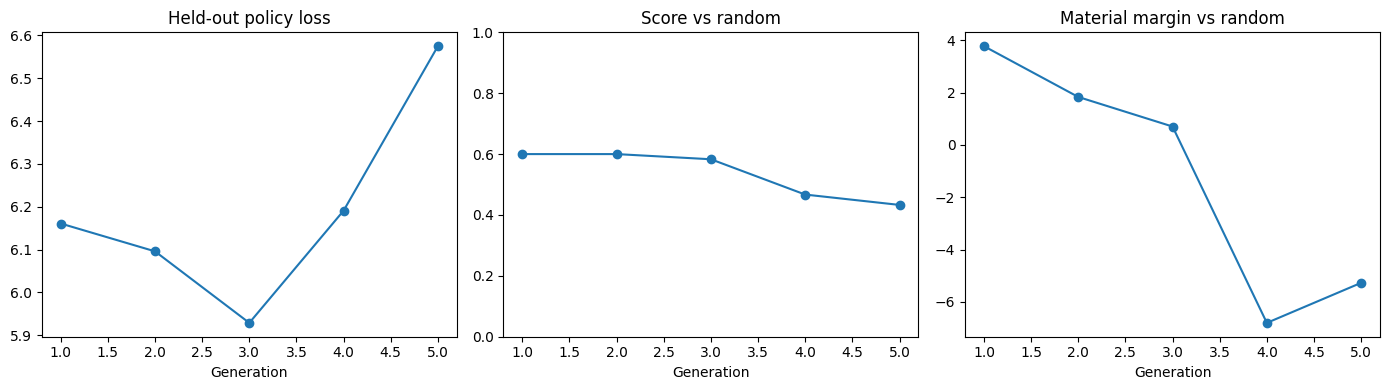

In [99]:
df=pd.read_csv("../logs/distill_metrics.csv")
fig,axes=plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(df["generation"], df["heldOutLoss"],marker="o")
axes[0].set_title("Held-out policy loss")
axes[1].plot(df["generation"], df["score"],marker="o")
axes[1].set_title("Score vs random")
axes[1].set_ylim(0, 1)
axes[2].plot(df["generation"], df["margin"],marker="o")
axes[2].set_title("Material margin vs random")
for ax in axes:
    ax.set_xlabel("Generation")
plt.tight_layout()
plt.savefig("../docs/distill_curves.png", dpi=200)
plt.show()

In [46]:
gen5Net = loadNet("../checkpoints/distill/gen_005.pt")

fresh = collectDistillationData(gen5Net, 300)
print("gen 5 policy loss on fresh positions from its own teacher:", policyLossOn(gen5Net, fresh))
print("gen 5 policy loss on the original held-out set:", policyLossOn(gen5Net, heldOut))
print("prior sharpness:", priorSharpness(gen5Net))

ablated = AblatedNet(gen5Net, uniformPolicy=True)
print("gen 5, policy ignored:",
      evaluateDetailed(makeMCTSPlayer(ablated, 25, 4.0), randomMove, numGames=30))

gen 5 policy loss on fresh positions from its own teacher: 2.432
gen 5 policy loss on the original held-out set: 6.563
prior sharpness: 9.45
gen 5, policy ignored: (2, 28, 0, 0.533, 7.47)


In [50]:
import io
import json
import requests
import zstandard

evalUrl = "https://database.lichess.org/lichess_db_eval.jsonl.zst"

def streamEvalLines(url, maxLines):
    response = requests.get(url, stream=True)
    response.raise_for_status()
    try:
        reader = zstandard.ZstdDecompressor().stream_reader(response.raw)
        textStream = io.TextIOWrapper(reader, encoding="utf-8")
        for lineNumber, line in enumerate(textStream):
            if lineNumber >= maxLines:
                break
            yield line
    finally:
        response.close()


def parseEvalLine(line):
    record = json.loads(line)
    best = max(record["evals"], key=lambda e: e["depth"])
    pv = best["pvs"][0]
    uci = pv["line"].split()[0]
    if "cp" in pv:
        cp = pv["cp"]
    else:
        cp = 100000 if pv["mate"] > 0 else -100000
    return record["fen"], uci, cp

In [51]:
import numpy as np

def buildEvalDataset(url, numPositions, valueScale=400):
    states = np.zeros((numPositions, 13, 8, 8), dtype=np.uint8)
    moves = np.zeros(numPositions, dtype=np.int16)
    values = np.zeros(numPositions, dtype=np.float32)
    kept = skippedInvalid = skippedOther = 0
    for line in streamEvalLines(url, numPositions * 2):
        if kept >= numPositions:
            break
        try:
            fen, uci, cp = parseEvalLine(line)
            board = chess.Board(fen)
            if not board.is_valid():
                skippedInvalid+=1
                continue
            move=board.parse_uci(uci)
        except Exception:
            skippedOther+=1
            continue
        whiteValue = math.tanh(cp / valueScale)
        states[kept] = boardToTensor(board).numpy().astype(np.uint8)
        moves[kept] = moveToIndex(move)
        values[kept] = whiteValue if board.turn == chess.WHITE else -whiteValue
        kept += 1
    return states[:kept], moves[:kept], values[:kept], skippedInvalid, skippedOther

In [ ]:
rows=[]
failures=0
for line in streamEvalLines(evalUrl, 20000):
    try:
        fen, uci, cp = parseEvalLine(line)
        board = chess.Board(fen)
        move = board.parse_uci(uci)
        rows.append((board, move, cp))
    except Exception:
        failures += 1

print("parsed:", len(rows), "failures:", failures)

#which perspective is the score in?
whiteMaterial,moverMaterial,scores=[],[],[]
for board,move,cp in rows:
    if abs(cp)>=5000:
        continue
    balance = materialBalance(board)
    whiteMaterial.append(balance)
    moverMaterial.append(balance if board.turn == chess.WHITE else -balance)
    scores.append(cp)

def corrList(a, b):
    return torch.corrcoef(torch.tensor([a, b], dtype=torch.float32))[0, 1].item()

print("corr(score, white material):", round(corrList(scores, whiteMaterial), 3))
print("corr(score, mover material):", round(corrList(scores, moverMaterial), 3))

#how varied are the positions?
pieceCounts = [len(board.piece_map()) for board, _, _ in rows]
print("pieces per position: min", min(pieceCounts), "average", round(sum(pieceCounts) / len(pieceCounts), 1), "max", max(pieceCounts))
print("white to move:", round(sum(b.turn == chess.WHITE for b, _, _ in rows) / len(rows), 3))
print("distinct best moves:", len({m.uci() for _, m, _ in rows}))

parsed: 20000 failures: 0
corr(score, white material): 0.27
corr(score, mover material): 0.023
pieces per position: min 3 average 21.1 max 51
white to move: 0.526
distinct best moves: 1645


In [52]:
states, moves, values, skippedInvalid, skippedOther = buildEvalDataset(evalUrl, 20000)
print("kept:", len(states), "| invalid skipped:", skippedInvalid, "| other failures:", skippedOther)
print("max pieces:", int(states[:, :12].sum(axis=(1, 2, 3)).max()))
print("value mean abs:", round(float(np.abs(values).mean()), 3),
      "| share above 0.9:", round(float((np.abs(values) > 0.9).mean()), 3))

weights = np.array([1, 3, 3, 5, 9, 0, -1, -3, -3, -5, -9, 0])
whiteBalance = (states[:, :12].sum(axis=(2, 3)) * weights).sum(axis=1)
moverBalance = np.where(states[:, 12, 0, 0] == 1, whiteBalance, -whiteBalance)
print("corr(value, mover material):", round(float(np.corrcoef(values, moverBalance)[0, 1]), 3))

kept: 20000 | invalid skipped: 125 | other failures: 0
max pieces: 32
value mean abs: 0.405 | share above 0.9: 0.259
corr(value, mover material): 0.546


In [53]:
agree=total=0
for line in streamEvalLines(evalUrl, 20000):
    fen, uci, cp = parseEvalLine(line)
    if abs(cp) != 100000:
        continue
    board = chess.Board(fen)
    if not board.is_valid():
        continue
    board.push(board.parse_uci(uci))
    if board.is_checkmate():
        total += 1
        moverWasWhite = board.turn == chess.BLACK
        agree += (cp > 0) == moverWasWhite
print("mate-in-one entries:", total, "| sign matches White's perspective:", agree)

mate-in-one entries: 300 | sign matches White's perspective: 300


In [55]:
def evaluateSupervised(net, states, moves, values, batchSize=1000):
    policyLoss=valueLoss=top1=top3=0.0
    predicted=[]
    with torch.no_grad():
        for i in range(0, len(states), batchSize):
            x=torch.from_numpy(states[i:i + batchSize]).float()
            y=torch.from_numpy(moves[i:i + batchSize].astype(np.int64))
            v=torch.from_numpy(values[i:i + batchSize]).unsqueeze(1)
            logits,value=net(x)
            policyLoss+=F.cross_entropy(logits, y, reduction="sum").item()
            valueLoss+=F.mse_loss(value, v, reduction="sum").item()
            top=logits.topk(3, dim=1).indices
            top1+=(top[:, 0] == y).sum().item()
            top3+=(top == y.unsqueeze(1)).any(dim=1).sum().item()
            predicted.append(value.flatten())
    n=len(states)
    valueCorr=torch.corrcoef(torch.stack([torch.cat(predicted), torch.from_numpy(values)]))[0, 1].item()
    return round(policyLoss / n, 3), round(valueLoss / n, 4), round(top1 / n, 3), round(top3 / n, 3), round(valueCorr, 3)


def trainSupervised(net, states, moves, values, numEpochs=5, batchSize=256, lr=1e-3, heldOutSize=2000):
    heldStates,heldMoves,heldValues=states[:heldOutSize], moves[:heldOutSize], values[:heldOutSize]
    trainStates,trainMoves,trainValues=states[heldOutSize:], moves[heldOutSize:], values[heldOutSize:]
    optimizer=optim.Adam(net.parameters(),lr=lr)
    numTrain=len(trainStates)
    for epoch in range(numEpochs):
        order=np.random.permutation(numTrain)
        for i in range(0, numTrain, batchSize):
            idx=order[i:i+batchSize]
            x=torch.from_numpy(trainStates[idx]).float()
            y=torch.from_numpy(trainMoves[idx].astype(np.int64))
            v=torch.from_numpy(trainValues[idx]).unsqueeze(1)
            logits,value=net(x)
            loss=F.cross_entropy(logits,y)+F.mse_loss(value,v)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(epoch,evaluateSupervised(net,heldStates,heldMoves,heldValues))
    return net

In [56]:
data=np.load("../data/eval_20k.npz")
states,moves,values=data["states"], data["moves"], data["values"]

supNet=ChessNet()
print("before training:", evaluateSupervised(supNet, states[:2000], moves[:2000], values[:2000]))
trainSupervised(supNet, states, moves, values, numEpochs=8)

before training: (8.318, 0.3541, 0.0, 0.0, 0.295)
0 (6.534, 0.3019, 0.021, 0.062, 0.465)
1 (6.282, 0.2656, 0.025, 0.072, 0.525)
2 (6.133, 0.2561, 0.044, 0.092, 0.534)
3 (6.004, 0.2591, 0.059, 0.117, 0.549)
4 (5.872, 0.2417, 0.068, 0.152, 0.587)
5 (5.829, 0.2453, 0.085, 0.17, 0.598)
6 (6.257, 0.248, 0.094, 0.181, 0.593)
7 (6.495, 0.2321, 0.094, 0.201, 0.615)


ChessNet(
  (conv1): Conv2d(13, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (policyConv): Conv2d(64, 8, kernel_size=(1, 1), stride=(1, 1))
  (policyHead): Linear(in_features=512, out_features=4096, bias=True)
  (valueHead): Linear(in_features=4096, out_features=1, bias=True)
)

In [57]:
import time

start=time.time()
bigStates,bigMoves,bigValues,skippedInvalid,skippedOther=buildEvalDataset(evalUrl,300000)
print("kept", len(bigStates), "| invalid", skippedInvalid, "| other", skippedOther, "| seconds", round(time.time() - start))
np.savez("../data/eval_300k.npz", states=bigStates, moves=bigMoves, values=bigValues)

kept 300000 | invalid 1426 | other 0 | seconds 206


In [58]:
def trainSupervisedRun(net, states, moves, values, runName, numEpochs=6, batchSize=256, lr=1e-3,
                       heldOutSize=5000, snapshotSteps=(0, 50, 200, 500, 1000, 2000)):
    os.makedirs("../logs", exist_ok=True)
    os.makedirs(f"../checkpoints/{runName}", exist_ok=True)
    heldStates,heldMoves,heldValues=states[:heldOutSize], moves[:heldOutSize], values[:heldOutSize]
    trainStates,trainMoves,trainValues=states[heldOutSize:], moves[heldOutSize:], values[heldOutSize:]
    numTrain=len(trainStates)
    stepsPerEpoch=(numTrain + batchSize - 1) // batchSize
    optimizer=optim.Adam(net.parameters(), lr=lr)
    scheduler=optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=numEpochs * stepsPerEpoch)

    logPath=f"../logs/{runName}_metrics.csv"
    with open(logPath, "w", newline="") as f:
        csv.writer(f).writerow(["epoch", "seconds", "policyLoss", "valueLoss", "top1", "top3", "valueCorr"])

    step=0
    bestTop1=0.0
    for epoch in range(1, numEpochs + 1):
        startTime=time.time()
        order=np.random.permutation(numTrain)
        for i in range(0, numTrain, batchSize):
            if step in snapshotSteps:
                torch.save(net.state_dict(), f"../checkpoints/{runName}/step_{step:06d}.pt")
            idx=order[i:i + batchSize]
            x=torch.from_numpy(trainStates[idx]).float()
            y=torch.from_numpy(trainMoves[idx].astype(np.int64))
            v=torch.from_numpy(trainValues[idx]).unsqueeze(1)
            logits,value=net(x)
            loss=F.cross_entropy(logits, y) + F.mse_loss(value, v)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
            step+=1
        metrics=evaluateSupervised(net, heldStates, heldMoves, heldValues)
        with open(logPath, "a", newline="") as f:
            csv.writer(f).writerow([epoch, round(time.time() - startTime), *metrics])
        torch.save(net.state_dict(), f"../checkpoints/{runName}/epoch_{epoch:02d}.pt")
        if metrics[2] > bestTop1:
            bestTop1 = metrics[2]
            torch.save(net.state_dict(), f"../checkpoints/{runName}/best.pt")
        print(epoch, round(time.time() - startTime), "s", metrics)
    return net

In [59]:
data=np.load("../data/eval_300k.npz")
bigStates,bigMoves,bigValues=data["states"], data["moves"], data["values"]

net300k=ChessNet()
trainSupervisedRun(net300k, bigStates, bigMoves, bigValues, runName="sup300k", numEpochs=6)

1 227 s (3.844, 0.1633, 0.15, 0.315, 0.732)
2 204 s (3.299, 0.1703, 0.192, 0.404, 0.715)
3 204 s (3.112, 0.1557, 0.215, 0.438, 0.741)
4 209 s (3.049, 0.1541, 0.237, 0.457, 0.743)
5 199 s (3.053, 0.1539, 0.24, 0.465, 0.744)
6 203 s (3.065, 0.1543, 0.241, 0.462, 0.743)


ChessNet(
  (conv1): Conv2d(13, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (policyConv): Conv2d(64, 8, kernel_size=(1, 1), stride=(1, 1))
  (policyHead): Linear(in_features=512, out_features=4096, bias=True)
  (valueHead): Linear(in_features=4096, out_features=1, bias=True)
)

In [60]:
supNet=loadNet("../checkpoints/sup300k/best.pt")

for cPuct in (1.5, 4.0):
    player=makeMCTSPlayer(supNet, numSimulations=25, cPuct=cPuct)
    print("supervised, cPuct", cPuct, evaluateDetailed(player, randomMove, numGames=30))

ablated=AblatedNet(supNet, uniformPolicy=True)
print("supervised, policy ignored:", evaluateDetailed(makeMCTSPlayer(ablated, 25, 1.5), randomMove, numGames=30))
print("prior sharpness:", priorSharpness(supNet))

supervised, cPuct 1.5 (17, 13, 0, 0.783, 15.57)
supervised, cPuct 4.0 (15, 15, 0, 0.75, 19.27)
supervised, policy ignored: (1, 29, 0, 0.517, 8.3)
prior sharpness: 14.25


In [69]:
import io
import chess.pgn
import chess.svg

def positionAnalysis(board,net,numSimulations=100,cPuct=1.5):
    if board.is_game_over():
        value= -1.0 if board.is_checkmate() else 0.0
        return {"terminal": True, "value": value, "bestMove": None, "bestIndex": None, "ranked": []}
    visitProbs,root=search(board, net, numSimulations, cPuct)
    ranked=sorted(root.children.items(), key=lambda kv: kv[1].visitCount, reverse=True)
    bestIndex,bestChild=ranked[0]
    return {
        "terminal": False,
        "value": -bestChild.value(),
        "bestMove": indexToMove(bestIndex, board),
        "bestIndex": bestIndex,
        "ranked": [(indexToMove(i, board), c.visitCount, -c.value()) for i, c in ranked[:3]],
    }

def staticValue(board, net):
    with torch.no_grad():
        _, value = net(boardToTensor(board).unsqueeze(0))
    return value.item()

def classifyMove(loss, playedIsBest, isSacrifice, gapToSecond, insight, wasInCheck):
    if playedIsBest and isSacrifice and not wasInCheck and insight >= 0.25:
        return "Brilliant"
    if playedIsBest and gapToSecond >= 0.15:
        return "Great"
    if playedIsBest or loss < 0.03:
        return "Best"
    if loss<0.06:
        return "Good"
    if loss<0.10:
        return "Inaccuracy"
    if loss<0.20:
        return "Mistake"
    return "Blunder"


def reviewGame(pgnText, net, numSimulations=100, cPuct=1.5):
    game = chess.pgn.read_game(io.StringIO(pgnText))
    board = game.board()
    moves = list(game.mainline_moves())
    positions = [board.copy()]
    for move in moves:
        board.push(move)
        positions.append(board.copy())

    analyses = [positionAnalysis(b, net, numSimulations, cPuct) for b in positions]

    rows = []
    for i, move in enumerate(moves):
        before, after = positions[i], positions[i + 1]
        mover = before.turn
        vBest = analyses[i]["value"]
        vPlayed = -analyses[i + 1]["value"]
        loss = max(0.0, vBest - vPlayed) / 2

        playedIsBest = analyses[i]["bestMove"] == move
        if playedIsBest:
            loss = 0.0
        ranked = analyses[i]["ranked"]
        gapToSecond = 0.0
        if len(ranked) > 1 and ranked[1][1] >= 3:
            gapToSecond = (ranked[0][2] - ranked[1][2]) / 2

        # sacrifice: the mover ends at least 2 points of material down after the opponent's best reply
        moverBefore = materialBalance(before) * (1 if mover == chess.WHITE else -1)
        reply = analyses[i + 1]["bestMove"]
        if reply is not None:
            afterReply = after.copy()
            afterReply.push(reply)
            moverAfter = materialBalance(afterReply) * (1 if mover == chess.WHITE else -1)
        else:
            moverAfter = moverBefore
        isSacrifice = (moverBefore - moverAfter) >= 2

        insight=0.0
        if not after.is_game_over():
            insight=vPlayed - (-staticValue(after, net))

        label = classifyMove(loss, playedIsBest, isSacrifice, gapToSecond, insight, before.is_check())
        whiteWin = (1 + (vPlayed if mover == chess.WHITE else -vPlayed)) / 2
        bestSan = before.san(analyses[i]["bestMove"]) if analyses[i]["bestMove"] else ""
        rows.append({
            "ply": i + 1,
            "side": "White" if mover == chess.WHITE else "Black",
            "move": before.san(move),
            "class": label,
            "loss": round(loss, 3),
            "insight": round(insight, 2),
            "whiteWin": round(whiteWin, 3),
            "best": bestSan,
        })
    return rows, positions, analyses, moves


def summarizeReview(rows):
    summary = {}
    for side in ("White", "Black"):
        mine = [r for r in rows if r["side"] == side]
        counts = {}
        for r in mine:
            counts[r["class"]] = counts.get(r["class"], 0) + 1
        meanLoss = sum(r["loss"] for r in mine) / max(1, len(mine))
        summary[side] = {"accuracy": round(max(0.0, 100 - 200 * meanLoss), 1), "counts": counts}
    return summary


def plotReview(rows, title="Game review", path=None):
    import matplotlib.pyplot as plt
    plies = [0] + [r["ply"] for r in rows]
    wins = [0.5] + [r["whiteWin"] for r in rows]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(plies, wins, color="#444444", linewidth=1.5)
    ax.axhline(0.5, color="#aaaaaa", linewidth=0.8)
    colors = {"Brilliant": "#1baca6", "Great": "#5c8bb0", "Inaccuracy": "#f7c631",
              "Mistake": "#e58f2a", "Blunder": "#ca3431"}
    for r in rows:
        if r["class"] in colors:
            ax.scatter(r["ply"], r["whiteWin"], color=colors[r["class"]], s=60, zorder=3, label=r["class"])
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    if unique:
        ax.legend(unique.values(), unique.keys(), loc="upper left", fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Move (ply)")
    ax.set_ylabel("White's expected score")
    ax.set_title(title)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=200)
    plt.show()


def renderMoveSvg(positions, analyses, moves, ply, path=None):
    before = positions[ply - 1]
    played = moves[ply - 1]
    best = analyses[ply - 1]["bestMove"]
    arrows = [chess.svg.Arrow(played.from_square, played.to_square, color="#ca3431cc")]
    if best is not None and best != played:
        arrows.append(chess.svg.Arrow(best.from_square, best.to_square, color="#2e9f4ecc"))
    svg = chess.svg.board(before, arrows=arrows, size=480)
    if path:
        open(path, "w").write(svg)
    return svg

,ply,side,move,class,loss,insight,whiteWin,best
0,1,White,e4,Best,0.022,0.01,0.510,d4
1,2,Black,e5,Best,0.000,0.06,0.509,c5
2,3,White,Nf3,Best,0.000,0.06,0.526,d4
3,4,Black,d6,Best,0.018,-0.03,0.544,Nf6
4,5,White,d4,Best,0.000,0.03,0.541,d4
5,6,Black,Bg4,Good,0.032,0.10,0.573,exd4
6,7,White,dxe5,Best,0.000,-0.01,0.549,dxe5
7,8,Black,Bxf3,Inaccuracy,0.069,-0.11,0.617,dxe5
8,9,White,Qxf3,Best,0.000,0.10,0.579,Qxf3
9,10,Black,dxe5,Best,0.000,0.02,0.579,dxe5


{'White': {'accuracy': 97.6, 'counts': {'Best': 14, 'Good': 2, 'Inaccuracy': 1}}, 'Black': {'accuracy': 91.9, 'counts': {'Best': 9, 'Good': 2, 'Inaccuracy': 3, 'Mistake': 2}}}


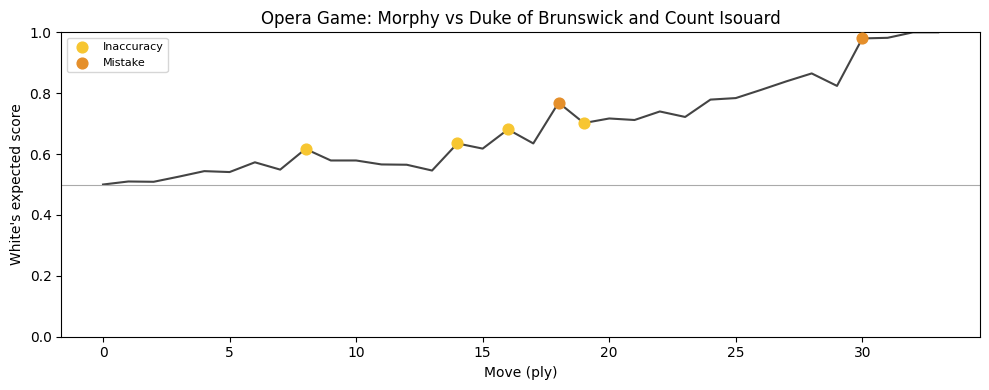

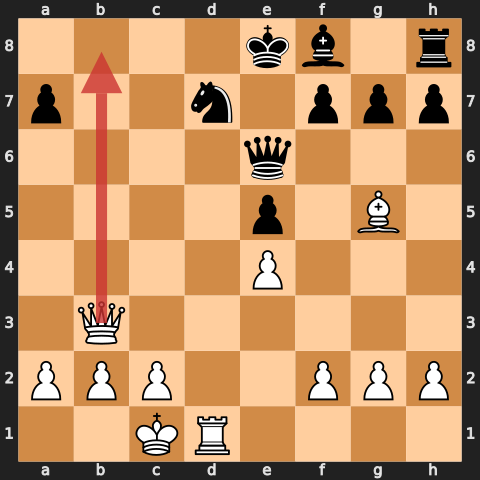

In [66]:
import pandas as pd
from IPython.display import SVG, display

operaGame = """[Event "Opera Game"]
[White "Paul Morphy"]
[Black "Duke of Brunswick and Count Isouard"]
[Result "1-0"]

1. e4 e5 2. Nf3 d6 3. d4 Bg4 4. dxe5 Bxf3 5. Qxf3 dxe5 6. Bc4 Nf6 7. Qb3 Qe7 8. Nc3 c6 9. Bg5 b5 10. Nxb5 cxb5 11. Bxb5+ Nbd7 12. O-O-O Rd8 13. Rxd7 Rxd7 14. Rd1 Qe6 15. Bxd7+ Nxd7 16. Qb8+ Nxb8 17. Rd8# 1-0
"""

supNet=loadNet("../checkpoints/sup300k/best.pt")
rows,positions,analyses,moves=reviewGame(operaGame,supNet,numSimulations=100)

display(pd.DataFrame(rows))
print(summarizeReview(rows))
plotReview(rows, "Opera Game: Morphy vs Duke of Brunswick and Count Isouard")
display(SVG(renderMoveSvg(positions, analyses, moves, 31)))

{'White': {'accuracy': 95.9, 'counts': {'Best': 48, 'Mistake': 7, 'Good': 2, 'Great': 1, 'Inaccuracy': 2}}, 'Black': {'accuracy': 92.6, 'counts': {'Best': 35, 'Good': 4, 'Mistake': 9, 'Inaccuracy': 7, 'Great': 2, 'Blunder': 1, 'Brilliant': 2}}}


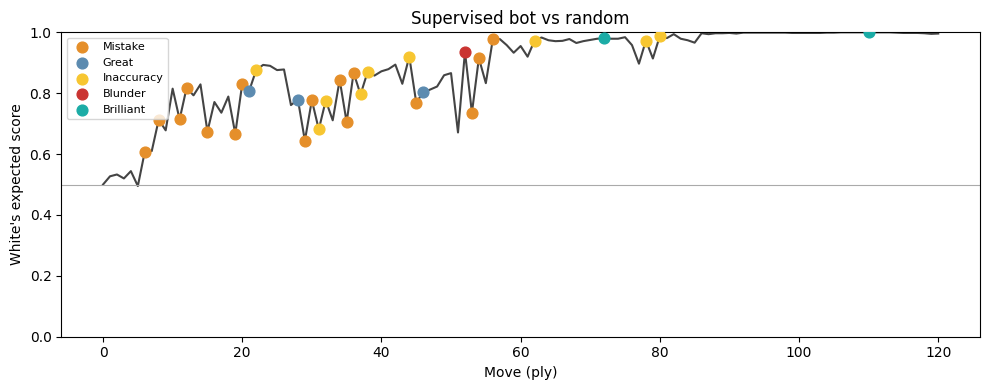

In [64]:
result,board=playGameCapped(makeMCTSPlayer(supNet, 25, 1.5), randomMove, maxPlies=120)
saveGame(board, "../games/review_demo.pgn", white="Supervised bot", black="Random")
pgnText=open("../games/review_demo.pgn").read()

rows2, positions2, analyses2, moves2 = reviewGame(pgnText, supNet, numSimulations=100)
print(summarizeReview(rows2))
plotReview(rows2, "Supervised bot vs random", path="../docs/review_example.png")

{'White': {'accuracy': 98.1, 'counts': {'Best': 56, 'Good': 1, 'Mistake': 2, 'Blunder': 1}}, 'Black': {'accuracy': 93.5, 'counts': {'Best': 43, 'Good': 7, 'Inaccuracy': 4, 'Mistake': 4, 'Blunder': 2}}}


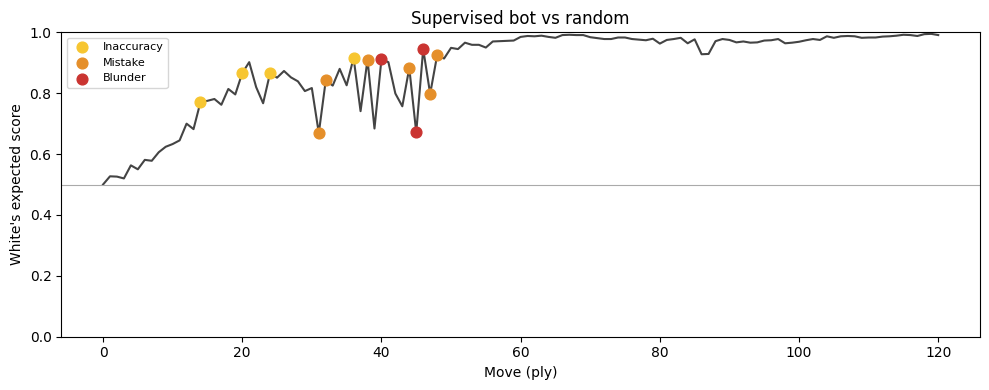

In [68]:
result, board = playGameCapped(makeMCTSPlayer(supNet, 25, 1.5), randomMove, maxPlies=120)
saveGame(board, "../games/review_demo.pgn", white="Supervised bot", black="Random")
pgnText = open("../games/review_demo.pgn").read()

rows2, positions2, analyses2, moves2 = reviewGame(pgnText, supNet, numSimulations=100)
print(summarizeReview(rows2))
plotReview(rows2, "Supervised bot vs random", path="../docs/review_example.png")

Immortal Game {'White': {'accuracy': 90.5, 'counts': {'Best': 11, 'Mistake': 5, 'Good': 2, 'Inaccuracy': 4, 'Great': 1}}, 'Black': {'accuracy': 84.5, 'counts': {'Best': 8, 'Mistake': 8, 'Good': 4, 'Blunder': 1, 'Inaccuracy': 1}}}


,ply,side,move,class,loss,insight,whiteWin,best
4,5,White,Bc4,Mistake,0.181,-0.24,0.348,Nf3
7,8,Black,b5,Mistake,0.122,-0.05,0.454,d5
8,9,White,Bxb5,Mistake,0.108,0.03,0.346,Bxf7+
9,10,Black,Nf6,Mistake,0.109,-0.14,0.455,Nc6
11,12,Black,Qh6,Mistake,0.169,0.01,0.578,Bc5
13,14,Black,Nh5,Mistake,0.147,-0.02,0.653,Bc5
14,15,White,Nh4,Mistake,0.102,0.03,0.551,Nc3
16,17,White,Nf5,Mistake,0.153,-0.10,0.457,Qxh5
21,22,Black,cxb5,Mistake,0.102,-0.08,0.560,Qxg4
23,24,Black,Qg6,Mistake,0.100,0.10,0.612,Qxh4


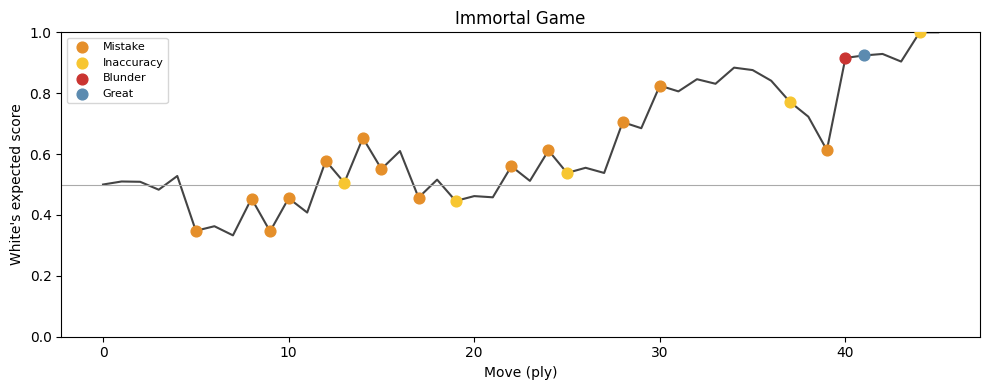

Evergreen Game {'White': {'accuracy': 93.8, 'counts': {'Best': 14, 'Inaccuracy': 3, 'Mistake': 2, 'Good': 3, 'Brilliant': 1, 'Great': 1}}, 'Black': {'accuracy': 90.6, 'counts': {'Best': 12, 'Inaccuracy': 6, 'Good': 2, 'Mistake': 2, 'Blunder': 1}}}


,ply,side,move,class,loss,insight,whiteWin,best
21,22,Black,b5,Mistake,0.128,-0.28,0.730,O-O
22,23,White,Qxb5,Mistake,0.156,-0.10,0.574,Bxe7
35,36,Black,Rg8,Mistake,0.121,-0.04,0.798,Kd8
36,37,White,Rad1,Mistake,0.118,-0.06,0.680,Bf5
39,40,Black,Nxe7,Blunder,0.221,-0.28,0.867,Kd8
40,41,White,Qxd7+,Brilliant,0.000,0.38,0.872,Qxd7+
42,43,White,Bf5+,Great,0.000,1.24,0.962,Bf5+


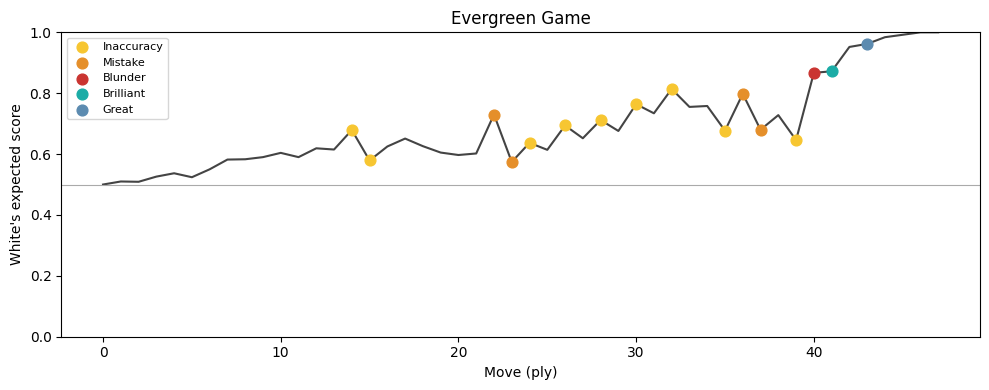

In [70]:
immortalGame = """[Event "Immortal Game"]
[White "Adolf Anderssen"]
[Black "Lionel Kieseritzky"]
[Result "1-0"]

1. e4 e5 2. f4 exf4 3. Bc4 Qh4+ 4. Kf1 b5 5. Bxb5 Nf6 6. Nf3 Qh6 7. d3 Nh5 8. Nh4 Qg5 9. Nf5 c6 10. g4 Nf6 11. Rg1 cxb5 12. h4 Qg6 13. h5 Qg5 14. Qf3 Ng8 15. Bxf4 Qf6 16. Nc3 Bc5 17. Nd5 Qxb2 18. Bd6 Bxg1 19. e5 Qxa1+ 20. Ke2 Na6 21. Nxg7+ Kd8 22. Qf6+ Nxf6 23. Be7# 1-0
"""

evergreenGame = """[Event "Evergreen Game"]
[White "Adolf Anderssen"]
[Black "Jean Dufresne"]
[Result "1-0"]

1. e4 e5 2. Nf3 Nc6 3. Bc4 Bc5 4. b4 Bxb4 5. c3 Ba5 6. d4 exd4 7. O-O d3 8. Qb3 Qf6 9. e5 Qg6 10. Re1 Nge7 11. Ba3 b5 12. Qxb5 Rb8 13. Qa4 Bb6 14. Nbd2 Bb7 15. Ne4 Qf5 16. Bxd3 Qh5 17. Nf6+ gxf6 18. exf6 Rg8 19. Rad1 Qxf3 20. Rxe7+ Nxe7 21. Qxd7+ Kxd7 22. Bf5+ Ke8 23. Bd7+ Kf8 24. Bxe7# 1-0
"""

for name, pgn in [("Immortal Game", immortalGame), ("Evergreen Game", evergreenGame)]:
    r, pos, an, mv = reviewGame(pgn, supNet, numSimulations=100)
    print(name, summarizeReview(r))
    display(pd.DataFrame(r)[pd.DataFrame(r)["class"].isin(["Brilliant", "Great", "Mistake", "Blunder"])])
    plotReview(r, name, path=f"../docs/review_{name.split()[0].lower()}.png")

In [71]:
def printNotable(name, rows):
    print(name)
    for r in rows:
        if r["class"] in ("Brilliant", "Great", "Mistake", "Blunder"):
            print(r["ply"], r["side"], r["move"], r["class"], "loss", r["loss"], "insight", r["insight"], "best", r["best"])


for name, pgn in [("Immortal Game", immortalGame), ("Evergreen Game", evergreenGame)]:
    r100, *_ = reviewGame(pgn, supNet, numSimulations=100)
    r200, *_ = reviewGame(pgn, supNet, numSimulations=200)
    same = sum(a["class"] == b["class"] for a, b in zip(r100, r200))
    print(name, "label agreement between 100 and 200 simulations:", same, "of", len(r100))
    printNotable(name + " (200 simulations)", r200)

Immortal Game label agreement between 100 and 200 simulations: 31 of 45
Immortal Game (200 simulations)
5 White Bc4 Mistake loss 0.183 insight -0.26 best Nf3
8 Black b5 Mistake loss 0.137 insight -0.04 best d5
12 Black Qh6 Mistake loss 0.19 insight 0.03 best Ng4
14 Black Nh5 Mistake loss 0.111 insight 0.01 best Be7
17 White Nf5 Mistake loss 0.106 insight -0.05 best Qxh5
28 Black Ng8 Mistake loss 0.151 insight -0.04 best Nc6
30 Black Qf6 Mistake loss 0.12 insight 0.03 best Nc6
35 White Bd6 Mistake loss 0.149 insight -0.29 best Nxg7+
37 White e5 Mistake loss 0.137 insight -0.28 best Nde7
40 Black Na6 Blunder loss 0.267 insight -0.42 best Nc6
41 White Nxg7+ Great loss 0.0 insight 0.48 best Nxg7+
45 White Be7# Great loss 0.0 insight 0.0 best Be7#
Evergreen Game label agreement between 100 and 200 simulations: 34 of 47
Evergreen Game (200 simulations)
36 Black Rg8 Mistake loss 0.103 insight -0.03 best Kd8
37 White Rad1 Mistake loss 0.104 insight -0.04 best Be4
40 Black Nxe7 Blunder loss 0.2